In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.pricing import (
    black_scholes_call,
    monte_carlo_call,
    monte_carlo_call_antithetic
)

S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

prix_reference = black_scholes_call(S0, K, T, r, sigma)

print("Prix Black-Scholes :", prix_reference)



Prix Black-Scholes : 10.450583572185565


In [5]:
n_values = [100, 500, 1000, 5000, 10000, 50000, 100000]

results = []

for N in n_values:

    # Monte-Carlo standard
    standard = monte_carlo_call(
        S0, K, T, r, sigma,
        n_simulations=N,
        seed=42
    )

    # Monte-Carlo antithétique
    antithetic = monte_carlo_call_antithetic(
        S0, K, T, r, sigma,
        n_pairs=N // 2,
        seed=42
    )

    results.append({
        "N": N,
        "Prix standard": standard["price"],
        "Prix antithétique": antithetic["price"],
        "Erreur standard": standard["standard_error"],
        "Erreur antithétique": antithetic["standard_error"]
    })

df = pd.DataFrame(results)

display(df)

,N,Prix standard,Prix antithétique,Erreur standard,Erreur antithétique
0,100,7.825768,8.286818,1.011962,0.733399
1,500,9.868363,9.843097,0.635871,0.433104
2,1000,9.911980,10.000398,0.448345,0.313601
3,5000,10.168920,10.450949,0.205861,0.150468
4,10000,10.345182,10.410052,0.147663,0.104872
5,50000,10.457692,10.454935,0.066143,0.046749
6,100000,10.420541,10.467314,0.046770,0.033077


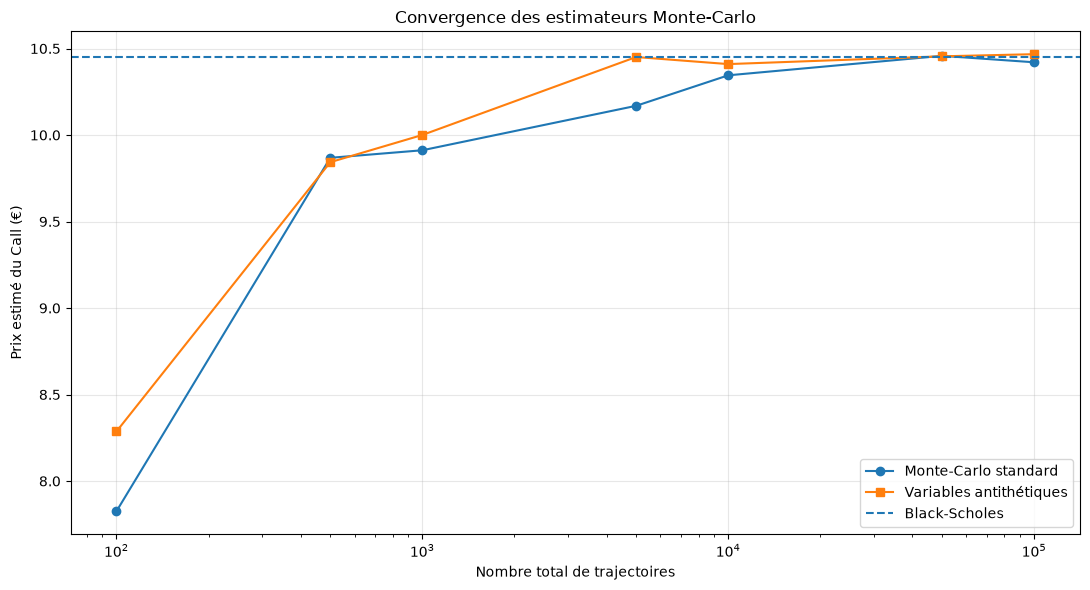

In [6]:

plt.figure(figsize=(11, 6))

plt.plot(
    df["N"],
    df["Prix standard"],
    marker="o",
    label="Monte-Carlo standard"
)

plt.plot(
    df["N"],
    df["Prix antithétique"],
    marker="s",
    label="Variables antithétiques"
)

plt.axhline(
    y=prix_reference,
    linestyle="--",
    label="Black-Scholes"
)

plt.xscale("log")

plt.xlabel("Nombre total de trajectoires")
plt.ylabel("Prix estimé du Call (€)")

plt.title("Convergence des estimateurs Monte-Carlo")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../figures/convergence_monte_carlo.png", dpi=300)
plt.show()


In [13]:
from src.pricing import monte_carlo_asian_call

asian = monte_carlo_asian_call(
    S0=100,
    K=100,
    T=1,
    r=0.05,
    sigma=0.20,
    n_simulations=50_000,
    n_steps=252,
    seed=42
)

print("Prix du Call asiatique :", asian["price"])
print("Erreur standard :", asian["standard_error"])
print("Intervalle de confiance :", asian["confidence_interval"])

Prix du Call asiatique : 5.838918415222987
Erreur standard : 0.03602069975020574
Intervalle de confiance : (5.768317843712584, 5.90951898673339)


In [14]:
from src.pricing import monte_carlo_asian_call

asian = monte_carlo_asian_call(
    S0=100,
    K=100,
    T=1,
    r=0.05,
    sigma=0.20,
    n_simulations=50_000,
    n_steps=252,
    seed=42
)

print("PRICING OPTION ASIATIQUE")
print("------------------------")
print("Prix :", round(asian["price"], 6))
print("Erreur standard :", round(asian["standard_error"], 6))
print("IC 95 % :", asian["confidence_interval"])

PRICING OPTION ASIATIQUE
------------------------
Prix : 5.838918
Erreur standard : 0.036021
IC 95 % : (5.768317843712584, 5.90951898673339)


In [16]:
european = black_scholes_call(
    100, 100, 1, 0.05, 0.20
)

print("Call européen :", round(european, 6))
print("Call asiatique :", round(asian["price"], 6))

print(
    "Différence :",
    round(european - asian["price"], 6)
)

Call européen : 10.450584
Call asiatique : 5.838918
Différence : 4.611665


In [17]:
from src.pricing import (
    black_scholes_call,
    monte_carlo_asian_call
)

# Paramètres du marché
S0 = 100
K = 100
T = 1
r = 0.05
sigma = 0.20

# Prix européen
european = black_scholes_call(
    S0, K, T, r, sigma
)

# Prix asiatique
asian = monte_carlo_asian_call(
    S0, K, T, r, sigma,
    n_simulations=100_000,
    n_steps=252,
    seed=42
)

print("PRICING COMPARATIF")
print("--------------------------")
print("Call européen :", round(european, 6))
print("Call asiatique :", round(asian["price"], 6))
print("Erreur standard :", round(asian["standard_error"], 6))
print("IC 95 % :", asian["confidence_interval"])
print("Différence :", round(european - asian["price"], 6))

PRICING COMPARATIF
--------------------------
Call européen : 10.450584
Call asiatique : 5.786512
Erreur standard : 0.025338
IC 95 % : (5.736849828012812, 5.836173953258334)
Différence : 4.664072


In [18]:
steps_values = [12, 52, 252]

asian_results = []

for steps in steps_values:

    result = monte_carlo_asian_call(
        S0, K, T, r, sigma,
        n_simulations=100_000,
        n_steps=steps,
        seed=42
    )

    asian_results.append({
        "Observations": steps,
        "Prix asiatique": result["price"],
        "Erreur standard": result["standard_error"]
    })

df_asian = pd.DataFrame(asian_results)

display(df_asian)

,Observations,Prix asiatique,Erreur standard
0,12,6.164991,0.026990
1,52,5.910310,0.025893
2,252,5.786512,0.025338
